In [1]:

## STEP 1: Load all files and check them

# Input: 4 CSV files (ERP cluster RS, component RS, spectral RS, clinical/demographic)
# Output: 4 cleaned DataFrames — ID-ASD/ID-control excluded, missing codes (777/999) set to NaN, N2 columns dropped, Age_Group standardised

import pandas as pd
import numpy as np

# Load spectral data
spectral_data = pd.read_csv('C:/Users/cigde/Dropbox/Habituation_paper/October_Emily/input_arrays/pls_regression/spectral_RS_all_ages.csv', dtype={'UniqueID': str})

# Load clinical data
clinical_data = pd.read_csv('C:/Users/cigde/Dropbox/Habituation_paper/October_Emily/input_arrays/pls_regression/demog_clin_data.csv', dtype={'UniqueID': str})

# Convert IDs to string
clinical_data['UniqueID'] = clinical_data['UniqueID'].astype(str)

# Filter out ID-ASD and ID-control
clinical_data_filtered = clinical_data[
    ~clinical_data['group_original'].isin(['ID-ASD', 'ID-control'])
].copy()

# Replace missing codes
clinical_data_filtered = clinical_data_filtered.replace([777, 999], np.nan)

## Step 1b: Sort clinical data
age_order = {'Child': 1, 'Adolescent': 2, 'Adult': 3}
group_order = {'TD': 1, 'ASD': 2}
clinical_data_filtered['age_sort'] = clinical_data_filtered['schedule_adj'].map(age_order)
clinical_data_filtered['group_sort'] = clinical_data_filtered['group_original'].map(group_order)
clinical_data_filtered_sorted = clinical_data_filtered.sort_values(
    by=['age_sort', 'group_sort']
).reset_index(drop=True)
clinical_data_filtered_sorted = clinical_data_filtered_sorted.drop(['age_sort', 'group_sort'], axis=1)


# Standardise Age_Group capitalisation to title case across all files
spectral_data['Age_Group'] = spectral_data['Age_Group'].str.title()


# print("\n" + "="*70)
# print("Spectral RS Data:")
# print(spectral_data.head(3))
# print(f"Shape: {spectral_data.shape} | Columns: {spectral_data.columns.tolist()}")

# print("\n" + "="*70)
# print("Clinical Data:")
# print(clinical_data_filtered_sorted[['UniqueID', 'group_original', 'schedule_adj',
#                                       'age_years', 'fsiq', 'SRS_tscore']].head(3))
# print(f"Shape: {clinical_data_filtered_sorted.shape}")
# print(f"Group counts: {clinical_data_filtered_sorted['group_original'].value_counts()}")


In [2]:
## STEP 2a: Merge spectral and clinical files on UniqueID

# Input: 4 DataFrames from STEP 1
# Output: Single merged DataFrame with all EEG + clinical variables, duplicate columns removed

# Step 2a: Standardise age_group capitalisation to lowercase for merging
spectral_data['Age_Group'] = spectral_data['Age_Group'].str.lower()

# keep spectral features that wil be used in the clsreing
eeg_features = [
    'power_slow_poststim_diff','power_fast_theta_poststim_diff','power_alpha_poststim_diff',
    'power_low_beta_poststim_diff','power_high_beta_poststim_diff',
    'itpc_slow_poststim_diff','itpc_fast_theta_poststim_diff','itpc_alpha_poststim_diff',
    'itpc_low_beta_poststim_diff','itpc_high_beta_poststim_diff',
]
spectral_data = spectral_data.drop(columns=[c for c in spectral_data.columns
                if c.startswith(('power_','itpc_')) and c not in eeg_features])
print(spectral_data.columns.tolist())



['SubjectID', 'UniqueID', 'Group', 'Age_Group', 'power_slow_poststim_diff', 'power_fast_theta_poststim_diff', 'power_alpha_poststim_diff', 'power_low_beta_poststim_diff', 'power_high_beta_poststim_diff', 'itpc_slow_poststim_diff', 'itpc_fast_theta_poststim_diff', 'itpc_alpha_poststim_diff', 'itpc_low_beta_poststim_diff', 'itpc_high_beta_poststim_diff']


In [3]:
# Step 2b: Merge with clinical on UniqueID
merged_data = pd.merge(spectral_data, clinical_data_filtered_sorted, on='UniqueID', how='inner')

# Step 2c: Clean up duplicate columns
cols_to_drop = ['Group', 'Age_Group', 'group', 'schedule_enrol', 'age']

merged_data = merged_data.drop(columns=cols_to_drop)

# Verify
print("MERGE SUMMARY:")
print("="*70)
print(f"Spectral RS subjects:   {len(spectral_data)}")
print(f"Clinical subjects:      {len(clinical_data_filtered_sorted)}")
print(f"Final merged subjects:  {len(merged_data)}")
print(f"\nBy group: {merged_data['group_original'].value_counts().to_dict()}")
print(f"Total columns: {len(merged_data.columns)}")
print(f"\nColumns: {merged_data.columns.tolist()}")

MERGE SUMMARY:
Spectral RS subjects:   372
Clinical subjects:      653
Final merged subjects:  372

By group: {'ASD': 201, 'TD': 171}
Total columns: 27

Columns: ['SubjectID', 'UniqueID', 'power_slow_poststim_diff', 'power_fast_theta_poststim_diff', 'power_alpha_poststim_diff', 'power_low_beta_poststim_diff', 'power_high_beta_poststim_diff', 'itpc_slow_poststim_diff', 'itpc_fast_theta_poststim_diff', 'itpc_alpha_poststim_diff', 'itpc_low_beta_poststim_diff', 'itpc_high_beta_poststim_diff', 'group_original', 'schedule_adj', 'sex', 'viq', 'piq', 'fsiq', 'age_years', 'CSS_total', 'SRS_tscore', 'SSP_tactile', 'SSP_audfilt', 'SSP_visualaudisens', 'SSP_total', 'SSP_hype', 'SSP_hypo']


In [4]:

# STEP 3a: Define EEG feature matrix and clinical variables
# Input: Merged DataFrame from STEP 2
# Output: EEG feature matrix (8 amplitude features, rows with missing EEG dropped), clinical variable list defined for later characterisation

# --- EEG features for clustering ---
eeg_features = [
    # Post-stimulus power difference
    'power_slow_poststim_diff',
    'power_fast_theta_poststim_diff',
    'power_alpha_poststim_diff',
    'power_low_beta_poststim_diff',
    'power_high_beta_poststim_diff',
    # Post-stimulus ITPC difference
    'itpc_slow_poststim_diff',
    'itpc_fast_theta_poststim_diff',
    'itpc_alpha_poststim_diff',
    'itpc_low_beta_poststim_diff',
    'itpc_high_beta_poststim_diff',
]

# --- Clinical variables for cluster characterisation (not entered into clustering) ---
clinical_features = ['age_years', 'viq', 'piq', 'fsiq', 'SRS_tscore', 'SSP_total', 'CSS_total']

# --- Extract EEG matrix and drop rows with any missing EEG values ---
X_eeg = merged_data[eeg_features].copy()
X_eeg_complete = X_eeg.dropna(axis=0, how='any')
dropped = len(X_eeg) - len(X_eeg_complete)

print(f"Total subjects before removal due to missing EEG features: {len(X_eeg)}")
print(f"Subjects dropped (missing EEG data): {dropped}")
print(f"Subjects retained for clustering: {len(X_eeg_complete)}")
print(f"Number of EEG features: {len(eeg_features)}")
print(f"\nMissingness per feature:\n{X_eeg.isna().sum()[X_eeg.isna().sum() > 0]}")


Total subjects before removal due to missing EEG features: 372
Subjects dropped (missing EEG data): 0
Subjects retained for clustering: 372
Number of EEG features: 10

Missingness per feature:
Series([], dtype: int64)


In [5]:
# STEP 3b: IQR-based outlier removal across all EEG features

# Input: Merged DataFrame filtered to subjects with complete EEG data
# Output: Cleaned DataFrame and updated EEG feature matrix with outliers removed

def remove_outliers_col(df, col):
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    return df[(df[col] >= Q1 - 2.5*IQR) & (df[col] <= Q3 + 2.5*IQR)]

# Start from full merged data, apply IQR removal iteratively across all EEG features
df_clean = merged_data.loc[X_eeg_complete.index].copy()

# Sanity check: confirm index alignment between df_clean and merged_data
assert all(df_clean.index.isin(merged_data.index)), "Index mismatch — df_clean contains indices not in merged_data"
assert all(df_clean['UniqueID'] == merged_data.loc[df_clean.index, 'UniqueID']), "UniqueID mismatch after index alignment"
print(f"Index alignment check passed — {len(df_clean)} subjects correctly aligned")

n_before = len(df_clean)

for col in eeg_features:
    df_clean = remove_outliers_col(df_clean, col)

n_after = len(df_clean)
print(f"Subjects before outlier removal: {n_before}")
print(f"Subjects after outlier removal:  {n_after}")
print(f"Subjects removed: {n_before - n_after}")

# Redefine X_eeg_complete from cleaned data
X_eeg_complete = df_clean[eeg_features].copy()
print(f"\nFeature matrix shape after outlier removal: {X_eeg_complete.shape}")

Index alignment check passed — 372 subjects correctly aligned
Subjects before outlier removal: 372
Subjects after outlier removal:  350
Subjects removed: 22

Feature matrix shape after outlier removal: (350, 10)


Age residualisation complete.
Feature matrix shape: (350, 10)
Running k=2...


C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


  k=2 done. Inertia=3070.4
Running k=3...


C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


  k=3 done. Inertia=2805.5
Running k=4...


C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


... (5 outputs left out)

C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


  k=7 done. Inertia=2290.9
Running k=8...


C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


  k=8 done. Inertia=2230.4


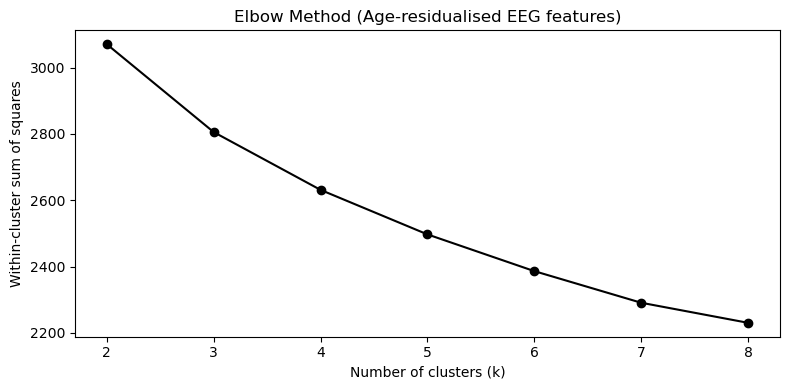

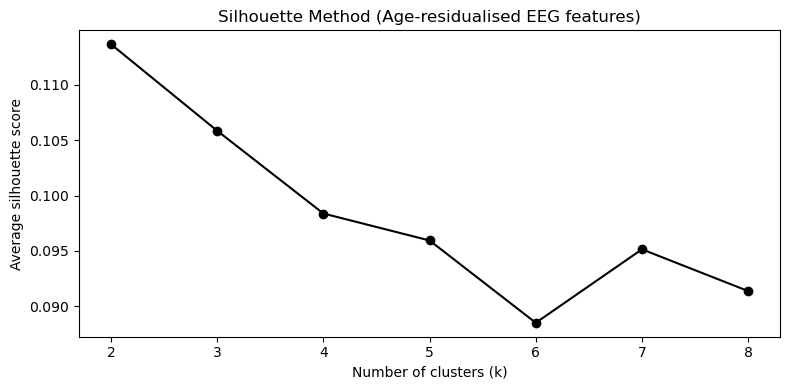


k | Inertia | Silhouette
2  | 3070.4  | 0.1137
3  | 2805.5  | 0.1059
4  | 2631.2  | 0.0984
5  | 2497.0  | 0.0959
6  | 2386.3  | 0.0885
7  | 2290.9  | 0.0951
8  | 2230.4  | 0.0914


In [6]:
# STEP 4: Age residualisation, standardisation, k selection

# Input: Cleaned EEG feature matrix + age variable
# Output: Age-residualised, z-scored feature matrix; elbow and silhouette plots for k=2–8

import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression

# --- Residualise age out of all EEG features ---
age = merged_data.loc[X_eeg_complete.index, 'age_years'].values.reshape(-1, 1)
X_eeg_resid = X_eeg_complete.copy()

for col in eeg_features:
    lr = LinearRegression()
    lr.fit(age, X_eeg_complete[col].values)
    X_eeg_resid[col] = X_eeg_complete[col].values - lr.predict(age)

print("Age residualisation complete.")
print(f"Feature matrix shape: {X_eeg_resid.shape}")

# --- Standardise residualised features ---
scaler_b = StandardScaler()
X_scaled_b = scaler_b.fit_transform(X_eeg_resid)

# --- Elbow and silhouette for k = 2 to 8 ---
k_range = range(2, 9)
inertia_b = []
silhouette_b = []

for k in k_range:
    print(f"Running k={k}...", flush=True)
    kmeans_b = KMeans(n_clusters=k, random_state=0, n_init=100)
    kmeans_b.fit(X_scaled_b)
    inertia_b.append(kmeans_b.inertia_)
    silhouette_b.append(silhouette_score(X_scaled_b, kmeans_b.labels_))
    print(f"  k={k} done. Inertia={kmeans_b.inertia_:.1f}")

# --- Elbow plot ---
plt.figure(figsize=(8, 4))
plt.plot(list(k_range), inertia_b, 'o-', color='black')
plt.title('Elbow Method (Age-residualised EEG features)')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Within-cluster sum of squares')
plt.grid(False)
plt.tight_layout()
plt.show()

# --- Silhouette plot ---
plt.figure(figsize=(8, 4))
plt.plot(list(k_range), silhouette_b, 'o-', color='black')
plt.title('Silhouette Method (Age-residualised EEG features)')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Average silhouette score')
plt.grid(False)
plt.tight_layout()
plt.show()

# --- Print scores ---
print("\nk | Inertia | Silhouette")
for k, iner, sil in zip(k_range, inertia_b, silhouette_b):
    print(f"{k}  | {iner:.1f}  | {sil:.4f}")

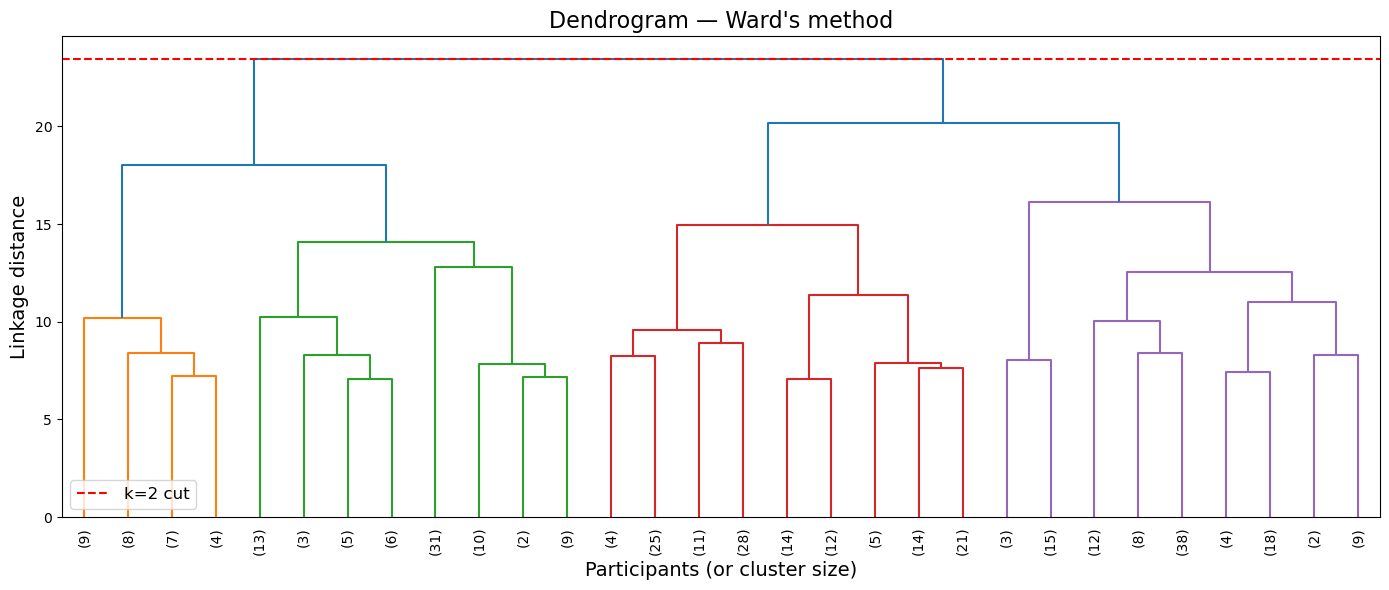


Cluster sizes:
  Cluster 1: 107
  Cluster 2: 243


In [7]:

# STEP 5: Hierarchical clustering (Complete Linkage method)
# Input: Z-scored age-residualised feature matrix (X_scaled_b)
# Output: Cluster labels assigned, df_clustered_b with cluster column, centroids computed

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

# --- Agglomerative clustering using "Complete Linkage method ---
Z = linkage(X_scaled_b, method='ward', metric='euclidean') # we can use ward or complete method for linkage
#Z = linkage(X_scaled_b, method='complete', metric='euclidean')

# --- Dendrogram with coloured subtrees ---
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10)
k = 2
plt.axhline(y=Z[-(k-1), 2], color='red', linestyle='--', linewidth=1.5, label='k=2 cut')
#plt.title("Dendrogram — Complete method", fontsize=16)
plt.title("Dendrogram — Ward's method", fontsize=16)
plt.xlabel('Participants (or cluster size)', fontsize=14)
plt.ylabel('Linkage distance', fontsize=14)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# --- Cut at k=2 ---
groupidx_b = fcluster(Z, t=k, criterion='maxclust')
df_clustered_b = merged_data.loc[X_eeg_complete.index].copy()
df_clustered_b['cluster'] = groupidx_b - 1  # 0-indexed to match k-means convention

print(f"\nCluster sizes:")
for c in range(k):
    print(f"  Cluster {c+1}: {np.sum(df_clustered_b['cluster'] == c)}")

# --- Centroids (mean of z-scored features per cluster) ---
cents_b = np.array([X_scaled_b[df_clustered_b['cluster'] == c].mean(axis=0) for c in range(k)])
groupidx_b = df_clustered_b['cluster'].values

In [8]:
## Step 5b: computes ARI between the hierarchical and k-means solutions on the same data.

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

kmeans_b = KMeans(n_clusters=2, random_state=0, n_init=100)
kmeans_labels = kmeans_b.fit_predict(X_scaled_b)

ari = adjusted_rand_score(kmeans_labels, df_clustered_b['cluster'])
print(f"Adjusted Rand Index: {ari:.4f}")

C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Adjusted Rand Index: 0.0661


In [9]:
# STEP 5c: Save cluster labels for cross-comparison between feature sets.
# Cluster numbering is arbitrary within each run, so these files are used
# to check whether the temporal and spectral analyses assign the same
# participants to the same groups (cross-tabulation and ARI, run separately).

import os
fig_path = r'C:/Users/cigde/Dropbox/Habituation_paper/October_Emily/final_figures'
df_clustered_b.reset_index()[['UniqueID', 'cluster']].to_csv(
    os.path.join(fig_path, 'labels_spectral_hierarchical.csv'), index=False)

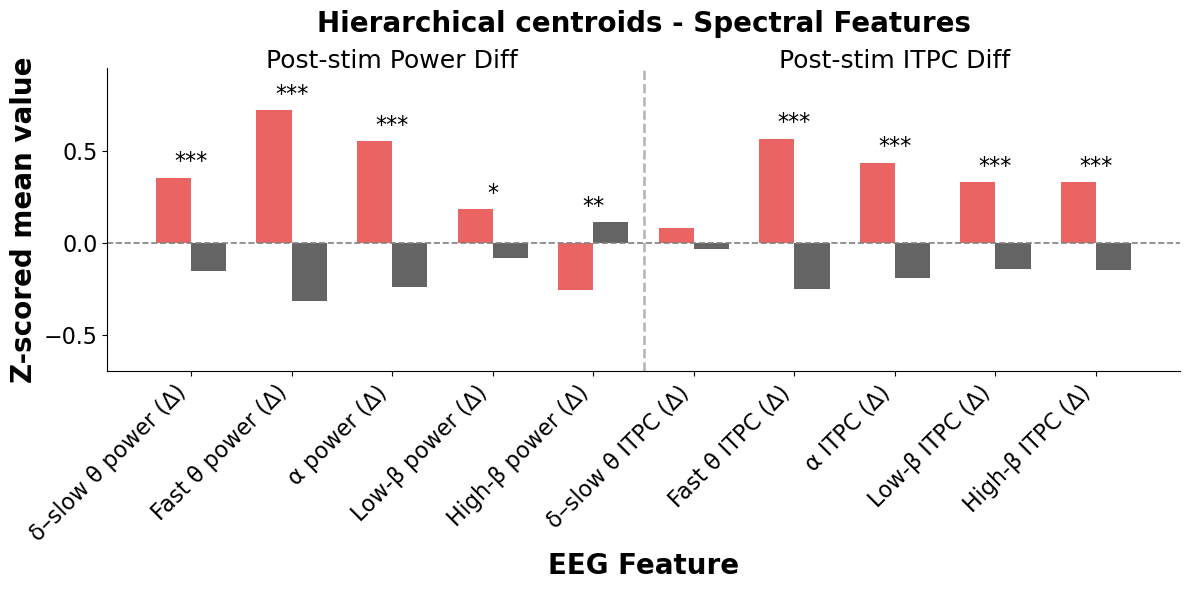

In [10]:
# Step 6:  Centroid profile plot (bar plot) 
# Input: Cluster centroids, cluster labels, EEG features
# Output: Bar plot showing z-scored centroid values per cluster with significance markers

from scipy import stats
import pandas as pd
import os
from statsmodels.stats.multitest import multipletests
import json

with open(r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\label_map.json', encoding='utf-8') as f:
    label_map = json.load(f)
new_labels = [label_map.get(f, f) for f in eeg_features]

# --- Stats for each EEG feature between clusters (BH-corrected) ---
pvals = []
for feat in eeg_features:
    c1_vals = X_eeg_resid.loc[df_clustered_b['cluster'] == 0, feat].dropna()
    c2_vals = X_eeg_resid.loc[df_clustered_b['cluster'] == 1, feat].dropna()
    _, p_norm1 = stats.shapiro(c1_vals)
    _, p_norm2 = stats.shapiro(c2_vals)
    if p_norm1 > 0.05 and p_norm2 > 0.05:
        _, p = stats.ttest_ind(c1_vals, c2_vals)
    else:
        _, p = stats.mannwhitneyu(c1_vals, c2_vals, alternative='two-sided')
    pvals.append(p)

_, p_fdr, _, _ = multipletests(pvals, method='fdr_bh')
sig_markers = ['***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
               for p in p_fdr]

# --- Bar plot ---
# font sizes
fs_tick  = 16
fs_label = 20
fs_title = 20

colors = ['#e32222', '#222222']
x = np.arange(len(eeg_features))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width/2, cents_b[0, :], width, color=colors[0], alpha=0.7, label='Cluster 1')
bars2 = ax.bar(x + width/2, cents_b[1, :], width, color=colors[1], alpha=0.7, label='Cluster 2')
ax.set_xticks(x)
ax.set_xticklabels(new_labels, rotation=45, ha='right', fontsize=fs_tick)
ax.tick_params(axis='y', labelsize=fs_tick)
ax.set_xlabel('EEG Feature', fontsize=fs_label, fontweight='bold')
ax.set_ylabel('Z-scored mean value', fontsize=fs_label, fontweight='bold')
ax.set_title('Hierarchical centroids - Spectral Features', fontsize=fs_title, fontweight='bold', pad=26)
ax.axhline(0, color='grey', linewidth=1.2, linestyle='--')

# --- Vertical separators ---
ax.axvline(4.5, color='grey', linewidth=1.8, linestyle='--', alpha=0.6)

# --- Significance markers ---
for i, marker in enumerate(sig_markers):
    if marker:
        y_pos = max(cents_b[0, i], cents_b[1, i]) + 0.05
        ax.text(i, y_pos, marker, ha='center', fontsize=16, color='black')

# --- Group labels ---
ax.set_ylim(-0.70, 0.95)
ax.text(2, 0.95, 'Post-stim Power Diff', ha='center', fontsize=18, color='black')
ax.text(7, 0.95, 'Post-stim ITPC Diff', ha='center', fontsize=18, color='black')

# ax.legend(fontsize=16, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()

fig_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\supplementary\suppl_fig_3'
os.makedirs(fig_path, exist_ok=True)

plt.savefig(os.path.join(fig_path, 'figure_suppl_3D.png'), format='png', dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure_suppl_3D.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure_suppl_3D.tiff'), format='tiff', dpi=300, bbox_inches='tight')

plt.show()

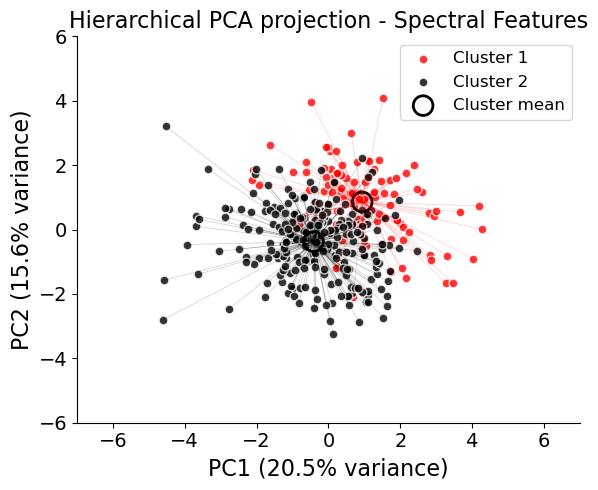

In [11]:

# STEP 7: PCA 2D visualisation
# Input: Z-scored feature matrix, cluster labels
# Output: Scatter plot of subjects in PC1/PC2 space with cluster centroids and connecting lines

from sklearn.decomposition import PCA
import os

# font sizes
fs_tick  = 14
fs_label = 16
fs_title = 16
fs_leg   = 12

colors = ['red', 'black']
pca_b = PCA(n_components=2)
data_2d_b = pca_b.fit_transform(X_scaled_b)
cents_2d_b = np.array([data_2d_b[groupidx_b == i].mean(axis=0) for i in range(k)])

fig, ax = plt.subplots(figsize=(6, 5))
for i, c in enumerate(colors):
    ax.scatter(data_2d_b[groupidx_b == i, 0], data_2d_b[groupidx_b == i, 1],
               color=c, edgecolor='w', s=40, alpha=0.8, label=f'Cluster {i+1}')
    for j in range(len(data_2d_b)):
        if groupidx_b[j] == i:
            ax.plot([data_2d_b[j, 0], cents_2d_b[i, 0]],
                    [data_2d_b[j, 1], cents_2d_b[i, 1]],
                    color=c, alpha=0.2, linewidth=0.5)
ax.scatter(cents_2d_b[:, 0], cents_2d_b[:, 1], facecolor='none', edgecolor='k',
           s=200, linewidth=2, marker='o', label='Cluster mean')
ax.set_title('Hierarchical PCA projection - Spectral Features', fontsize=fs_title)
ax.set_xlabel(f'PC1 ({pca_b.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=fs_label)
ax.set_ylabel(f'PC2 ({pca_b.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=fs_label)
ax.tick_params(axis='both', labelsize=fs_tick)
ax.legend(fontsize=fs_leg, loc='upper right')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlim(-7, 7)
ax.set_ylim(-6, 6)
plt.tight_layout()

fig_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\supplementary\suppl_fig_3'
os.makedirs(fig_path, exist_ok=True)

plt.savefig(os.path.join(fig_path, 'figure_suppl_3B.png'), format='png', dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure_suppl_3B.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure_suppl_3B.tiff'), format='tiff', dpi=300, bbox_inches='tight')

plt.show()

In [12]:
# Step 7b: Print PCA output

print(f"\nPCA variance explained: PC1={pca_b.explained_variance_ratio_[0]*100:.1f}%, "
      f"PC2={pca_b.explained_variance_ratio_[1]*100:.1f}%")
print("\nGroup distribution per cluster:")
print(pd.crosstab(df_clustered_b['cluster'], df_clustered_b['group_original']))
print("\nAge group distribution per cluster:")
print(pd.crosstab(df_clustered_b['cluster'], df_clustered_b['schedule_adj']))


PCA variance explained: PC1=20.5%, PC2=15.6%

Group distribution per cluster:
group_original  ASD   TD
cluster                 
0                56   51
1               134  109

Age group distribution per cluster:
schedule_adj  Adolescents  Adults  Children
cluster                                    
0                      47      31        29
1                      83      73        87


In [13]:
# STEP 8: Clinical variable descriptives per cluster
print("Cluster 1 vs Cluster 2 descriptives:")
for var in clinical_features:
    c1 = df_clustered_b[df_clustered_b['cluster'] == 0][var].dropna()
    c2 = df_clustered_b[df_clustered_b['cluster'] == 1][var].dropna()
    print(f"\n{var}:")
    print(f"  Cluster 1: M={c1.mean():.2f}, SD={c1.std():.2f}, N={len(c1)}")
    print(f"  Cluster 2: M={c2.mean():.2f}, SD={c2.std():.2f}, N={len(c2)}")

Cluster 1 vs Cluster 2 descriptives:

age_years:
  Cluster 1: M=16.00, SD=5.57, N=107
  Cluster 2: M=15.45, SD=5.79, N=243

viq:
  Cluster 1: M=103.78, SD=15.38, N=106
  Cluster 2: M=106.77, SD=15.04, N=236

piq:
  Cluster 1: M=105.65, SD=14.66, N=106
  Cluster 2: M=107.24, SD=15.03, N=239

fsiq:
  Cluster 1: M=104.82, SD=13.41, N=106
  Cluster 2: M=107.30, SD=13.22, N=238

SRS_tscore:
  Cluster 1: M=61.04, SD=15.30, N=79
  Cluster 2: M=60.01, SD=16.30, N=171

SSP_total:
  Cluster 1: M=156.12, SD=27.76, N=68
  Cluster 2: M=157.29, SD=29.31, N=131

CSS_total:
  Cluster 1: M=5.45, SD=2.59, N=47
  Cluster 2: M=5.03, SD=2.78, N=114


In [14]:

# Step 9: Permutation test for clinical differences 
from scipy import stats
import numpy as np

np.random.seed(42)
n_permutations = 10000

clinical_vars = ['age_years', 'viq', 'piq', 'fsiq', 'SRS_tscore', 'SSP_total', 'CSS_total']

observed_stats = {}
for var in clinical_vars:
    g0 = df_clustered_b.loc[df_clustered_b['cluster'] == 0, var].dropna().values
    g1 = df_clustered_b.loc[df_clustered_b['cluster'] == 1, var].dropna().values
    stat, _ = stats.mannwhitneyu(g0, g1, alternative='two-sided')
    observed_stats[var] = stat

perm_stats = {var: [] for var in clinical_vars}
for _ in range(n_permutations):
    shuffled_labels = df_clustered_b['cluster'].values.copy()
    np.random.shuffle(shuffled_labels)
    for var in clinical_vars:
        vals = df_clustered_b[var].dropna()
        idx = vals.index
        pos = np.array([df_clustered_b.index.get_loc(i) for i in idx])
        labels_aligned = shuffled_labels[pos] # get shuffled labels at matching non-NaN positions
        g0 = vals[labels_aligned == 0].values
        g1 = vals[labels_aligned == 1].values
        if len(g0) > 0 and len(g1) > 0:
            stat, _ = stats.mannwhitneyu(g0, g1, alternative='two-sided')
            perm_stats[var].append(stat)

print("="*70)
print(f"PERMUTATION TEST (n={n_permutations}) — observed vs null distribution")
print("="*70)
perm_pvalues = {}
for var in clinical_vars:
    obs = observed_stats[var]
    perms = np.array(perm_stats[var])
    perm_p = np.mean(np.abs(perms - np.mean(perms)) >= np.abs(obs - np.mean(perms)))
    perm_pvalues[var] = perm_p
    sig = ' ***' if perm_p < 0.001 else ' **' if perm_p < 0.01 else ' *' if perm_p < 0.05 else ''
    print(f"{var:<15} Observed stat: {obs:.1f}   Permutation p: {perm_p:.4f}{sig}")

PERMUTATION TEST (n=10000) — observed vs null distribution
age_years       Observed stat: 13797.0   Permutation p: 0.3630
viq             Observed stat: 11191.0   Permutation p: 0.1473
piq             Observed stat: 11959.5   Permutation p: 0.4349
fsiq            Observed stat: 11257.0   Permutation p: 0.1253
SRS_tscore      Observed stat: 7139.0   Permutation p: 0.3593
SSP_total       Observed stat: 4307.5   Permutation p: 0.7737
CSS_total       Observed stat: 2921.0   Permutation p: 0.5461


In [15]:
# Step 10: Save each clinical variable with permutation p < 0.05 per cluster (hierarchical, spectral) for plotting in the next script

save_path = 'C:/Users/cigde/Dropbox/Habituation_paper/October_Emily/final_figures/figure_7/'
sig_vars = [var for var in clinical_vars if perm_pvalues[var] < 0.05]

for var in sig_vars:
    sig_df = df_clustered_b[['UniqueID', 'cluster', var]].copy()
    sig_df['method'] = 'Hierarchical'
    sig_df['p_perm'] = perm_pvalues[var]
    sig_df.to_csv(save_path + f'{var}_hierarchical_spectral.csv', index=False)

print(f"Saved: {sig_vars}")

Saved: []


In [ ]:
## at this stage go to fig_7_clin_var_violin_plots script for plotting the significant variables between clusters 

In [ ]:
# STEP 11: Violin plots for significant clinical variables only  - Optional
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

clinical_labels = {
    'age_years': 'Age (years)',
    'viq': 'VIQ',
    'piq': 'PIQ',
    'fsiq': 'FSIQ',
    'SRS_tscore': 'SRS T-score',
    'SSP_total': 'SSP Total',
    'CSS_total': 'CSS Total'
}

cluster_colors = ['#e32222', '#222222']

# --- Only plot significant variables (p < 0.05), excluding age sanity check ---
sig_vars = [var for var in clinical_vars if var != 'age_years' and perm_pvalues[var] < 0.05]

#print(f"Significant clinical variables to plot: {sig_vars}")

n_vars = len(sig_vars)
if n_vars == 0:
    print("No significant clinical variables found.")
else:
    ncols = min(3, n_vars)
    nrows = int(np.ceil(n_vars / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows))
    axes = np.array(axes).flatten() if n_vars > 1 else [axes]

    for idx, var in enumerate(sig_vars):
        ax = axes[idx]

        c1 = df_clustered_b[df_clustered_b['cluster'] == 0][var].dropna()
        c2 = df_clustered_b[df_clustered_b['cluster'] == 1][var].dropna()

        # Stats
        p = perm_pvalues[var]
        test = '' # it will show permutation p value 

        # Violin plot
        parts = ax.violinplot([c1, c2], positions=[0, 1],
                              showmedians=True, showextrema=True)

        for i, pc in enumerate(parts['bodies']):
            pc.set_facecolor(cluster_colors[i])
            pc.set_alpha(0.6)
        parts['cmedians'].set_color('white')
        parts['cbars'].set_color('grey')
        parts['cmaxes'].set_color('grey')
        parts['cmins'].set_color('grey')

        # Individual data points
        for i, (data, pos) in enumerate(zip([c1, c2], [0, 1])):
            ax.scatter(np.random.normal(pos, 0.04, size=len(data)),
                       data, alpha=0.3, s=8, color=cluster_colors[i], zorder=2)

        # Significance annotation
        if p < 0.001:
            sig = '***'
        elif p < 0.01:
            sig = '**'
        elif p < 0.05:
            sig = '*'

        y_max = max(c1.max(), c2.max())
        y_range = y_max - min(c1.min(), c2.min())
        y_line = y_max + y_range * 0.05
        y_text = y_line + y_range * 0.02

        ax.plot([0, 0, 1, 1], [y_line, y_text, y_text, y_line],
                color='black', linewidth=1.2)
        ax.text(0.5, y_text, f'p={p:.4f}',
                ha='center', va='bottom', fontsize=13)

        ax.set_title(clinical_labels.get(var, var), fontsize=14, fontweight='bold', pad=20)
        ax.set_xticks([0, 1])
        ax.tick_params(axis='y', labelsize=12)
        ax.set_xticklabels(['Cluster 1', 'Cluster 2'], fontsize=13)
        ax.set_ylabel('Score', fontsize=14)
        ax.spines[['top', 'right']].set_visible(False)

    # Hide unused subplots
    for idx in range(n_vars, len(axes)):
        axes[idx].set_visible(False)

    fig.suptitle('Significant clinical variables across clusters (k=2, Spectral Features)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [ ]:
# STEP 11: Violin plots for clinical variable comparison across clusters - Optional

import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

clinical_labels = {
    'age_years': 'Age (years)',
    'viq': 'VIQ',
    'piq': 'PIQ',
    'fsiq': 'FSIQ',
    'SRS_tscore': 'SRS T-score',
    'SSP_total': 'SSP Total',
    'CSS_total': 'CSS Total'
}

cluster_colors = ['#e32222', '#222222']  # red for cluster 1, black for cluster 2

n_vars = len(clinical_features)
ncols = 4
nrows = int(np.ceil(n_vars / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
axes = axes.flatten()

for idx, var in enumerate(clinical_features):
    ax = axes[idx]

    c1 = df_clustered_b[df_clustered_b['cluster'] == 0][var].dropna()
    c2 = df_clustered_b[df_clustered_b['cluster'] == 1][var].dropna()

    # Stats
    p = perm_pvalues[var]
    test = '' # it will show permutation p value 

    # Violin plot
    parts = ax.violinplot([c1, c2], positions=[0, 1],
                          showmedians=True, showextrema=True)

    # Colour the violins
    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(cluster_colors[i])
        pc.set_alpha(0.6)
    parts['cmedians'].set_color('white')
    parts['cbars'].set_color('grey')
    parts['cmaxes'].set_color('grey')
    parts['cmins'].set_color('grey')

    # Add individual data points
    for i, (data, pos) in enumerate(zip([c1, c2], [0, 1])):
        ax.scatter(np.random.normal(pos, 0.04, size=len(data)),
                   data, alpha=0.3, s=8, color=cluster_colors[i], zorder=2)

    # Significance annotation
    if p < 0.001:
        sig = '***'
    elif p < 0.01:
        sig = '**'
    elif p < 0.05:
        sig = '*'
    else:
        sig = 'ns'

    y_max = max(c1.max(), c2.max())
    y_range = y_max - min(c1.min(), c2.min())
    y_line = y_max + y_range * 0.05
    y_text = y_line + y_range * 0.02

    if sig != 'ns':
        ax.plot([0, 0, 1, 1], [y_line, y_text, y_text, y_line],
                color='black', linewidth=1.2)
        ax.text(0.5, y_text, sig, ha='center', va='bottom', fontsize=13)
    else:
        ax.text(0.5, y_text, f'ns (p={p:.3f})', ha='center',
                va='bottom', fontsize=9, color='grey')

    # Labels
    ax.set_title(clinical_labels[var], fontsize=12, fontweight='bold')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Cluster 1', 'Cluster 2'], fontsize=10)
    ax.set_ylabel('Score', fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

    # Flag age as sanity check
    if var == 'age_years':
        ax.set_title('Age (years) [sanity check]', fontsize=10, color='grey')

# Hide unused subplots
for idx in range(n_vars, len(axes)):
    axes[idx].set_visible(False)

fig.suptitle('Clinical variable comparison across clusters (k=2, spectral features)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()